# Segurança pública inteligente em São Paulo — classificação de ocorrências com MLP
**Global Solution – Aprendizado Profundo com Redes Neurais Convolucionais**

**Tarefa:** dado um boletim de ocorrência de subtração de celular **já registrado** (ou hipotético) na cidade de São Paulo, classificar se ele é mais compatível com **roubo** ou **furto**.
> ⚠️ O modelo **não** prevê onde/quando um crime vai acontecer nem o risco de um crime. Ele classifica o *tipo* de uma ocorrência que já aconteceu.

**Fonte dos dados:** SSP-SP – Portal de Estatísticas, *Bases de Dados → Celulares subtraídos* (https://www.ssp.sp.gov.br/estatistica/consultas), arquivo `CelularesSubtraidos_2025.xlsx` (aba `CELULAR_2025`).

**Equipe:** Ana Clara Alcântara Lopes, Ana Flávia Couto Chaves, Izabely dos Santos Silva, Natalia Heloisa Rocha de Alcântara Bezerra e Raissa Marinho de Jesus Viana

**Aplicação web:** https://mlp-roubo-furto.onrender.com  
**Repositório:** https://github.com/flavsna/mlp-roubo-furto

## 1. Escolha da base, recorte e rótulo
| Decisão | Escolha | Justificativa |
|---|---|---|
| Base | Celulares subtraídos 2025 (SSP-SP) | Grande volume, com natureza do crime (rubrica) e campos de local/horário |
| Recorte geográfico | `CIDADE == 'S.PAULO'` | `CIDADE` é o município **do fato**. `NOME_MUNICIPIO` é onde o BO foi registrado (ex.: Delegacia Eletrônica) e **não** foi usado |
| Rótulo (`y`) | `RUBRICA`: Roubo (art. 157) = 1, Furto (art. 155) = 0 | Roubo envolve violência/grave ameaça; furto não |
| Exclusões | BOs com furto **e** roubo (ambíguos); outras rubricas; datas inconsistentes | Rótulo precisa ser inequívoco |
| Duplicidades | 1 linha por boletim (`ID_DELEGACIA`+`NUM_BO`+`ANO_BO`) | BO com vários celulares gera várias linhas |
| Amostra | 20.000 registros aleatórios (seed 42), proporção natural das classes | Sugerido pelo enunciado; viável para 4 h |

### Atributos de entrada (e por quê)
`bairro`, `tipo_local`, `subtipo_local`, `periodo`, `hora` (opcional), `dia_semana`, `mes`, `marca` do aparelho, `dias_registro` (dias entre o fato e o registro do BO) e `qtd` de aparelhos.
São características que descrevem **as circunstâncias da ocorrência**.

### Atributos excluídos (vazamento de dados / dados pessoais)
- `RUBRICA` (é o rótulo), `DESCR_CONDUTA`, `DESDOBRAMENTO`, `CIRCUNSTANCIA` → descrevem a natureza do crime (ex.: "com emprego de arma de fogo" só existe em roubo; "com rompimento de obstáculo" só em furto). **Vazamento direto.**
- `FLAG_FLAGRANTE`, `AUTORIA_BO`, `DESCRICAO_APRESENTACAO` (ex.: "registrado pela PM"), `FLAG_BLOQUEIO` → são consequências da natureza do crime/atendimento policial, não características do fato.
- `LOGRADOURO`, `NUMERO`, `CEP`, lat/long → endereço preciso (dado sensível/pessoal e muita ausência).

In [1]:
import sys, json, os, warnings, random
from pathlib import Path
warnings.filterwarnings('ignore'); os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
ROOT = Path('..').resolve() if Path('../src').exists() else Path('.').resolve()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from features import fit_spec, transform
from data_prep import build_dataset
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
FIG = ROOT / 'reports' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
(ROOT / 'model').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
print('TensorFlow', tf.__version__)

I0000 00:00:1794347434.323749    1407 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794347435.610676    1407 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 2. Carga, recorte e amostra
Se o `.xlsx` original estiver em `data/` (ou no caminho de upload) o recorte é refeito do zero; senão, usa-se a amostra já gerada (`data/amostra_sp_20k.csv`).

In [2]:
SAMPLE = ROOT / 'data' / 'amostra_sp_20k.csv'
xlsx = next((p for p in [ROOT/'data'/'CelularesSubtraidos_2025.xlsx', Path('/mnt/user-data/uploads/CelularesSubtraidos_2025.xlsx')] if p.exists()), None)
if xlsx is not None:
    raw = pd.read_excel(xlsx, sheet_name='CELULAR_2025')
    full, funil = build_dataset(raw)
    df = full.sample(20000, random_state=SEED).reset_index(drop=True)
    df.to_csv(SAMPLE, index=False)
    json.dump({**funil, 'amostra utilizada': len(df)}, open(ROOT/'data'/'funil.json', 'w'), ensure_ascii=False, indent=1)
else:
    df = pd.read_csv(SAMPLE)
funil = json.load(open(ROOT/'data'/'funil.json'))
pd.DataFrame({'registros': funil}).style.format('{:,}')

,registros
registros na base (estado de SP),"383,635"
fatos ocorridos em São Paulo (capital),"216,129"
rubrica = furto ou roubo,"183,798"
sem boletins ambíguos (furto+roubo),"183,657"
1 linha por boletim (sem duplicidades),"161,570"
"datas consistentes (2024-2025, registro >= fato)","161,354"
amostra utilizada,"20,000"


## 3. Exploração dos dados

(20000, 11)


,bairro,tipo_local,subtipo_local,marca,periodo,dia_semana,mes,hora,dias_registro,qtd,y
0,BOM RETIRO,Via Pública,Via Pública,Apple,Noite,4,10,20.5,4,1,0
1,LIBERDADE,Via Pública,Via Pública,Apple,Tarde,2,7,NaN,1,1,0
2,VILA LEOPOLDINA,Via Pública,Via Pública,Samsung,Noite,1,5,21.0,1,1,1



Valores ausentes:
hora    10295
dtype: int64

Distribuição da classe (1=roubo, 0=furto):
y
furto    0.628
roubo    0.372
Name: proportion, dtype: float64


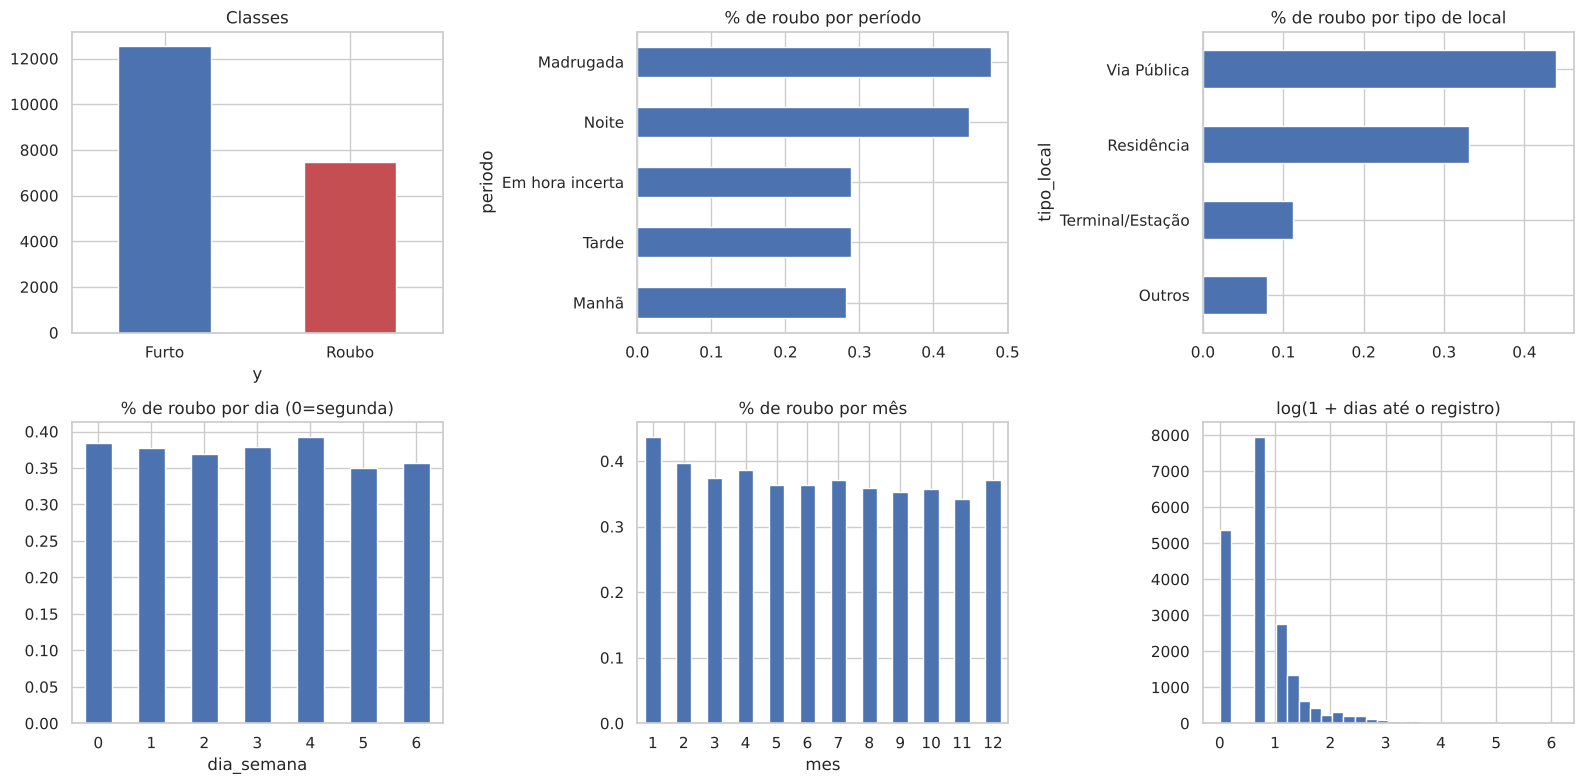

Registros com hora exata ausente: 51.5% (o período foi preenchido pelo campo DESCR_PERIODO)


In [3]:
print(df.shape); display(df.head(3))
print('\nValores ausentes:'); print(df.isna().sum()[lambda s: s>0])
print('\nDistribuição da classe (1=roubo, 0=furto):'); print(df.y.value_counts(normalize=True).rename({0:'furto',1:'roubo'}).round(3))
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
df.y.map({0:'Furto',1:'Roubo'}).value_counts().plot.bar(ax=ax[0,0], color=['#4c72b0','#c44e52'], rot=0, title='Classes')
df.groupby('periodo').y.mean().sort_values().plot.barh(ax=ax[0,1], title='% de roubo por período')
df.groupby('tipo_local').y.agg(['mean','size']).query('size>150')['mean'].sort_values().plot.barh(ax=ax[0,2], title='% de roubo por tipo de local')
df.groupby('dia_semana').y.mean().plot.bar(ax=ax[1,0], title='% de roubo por dia (0=segunda)', rot=0)
df.groupby('mes').y.mean().plot.bar(ax=ax[1,1], title='% de roubo por mês', rot=0)
np.log1p(df.dias_registro).hist(ax=ax[1,2], bins=30); ax[1,2].set_title('log(1 + dias até o registro)')
plt.tight_layout(); plt.savefig(FIG/'eda.png', dpi=130); plt.show()
print('Registros com hora exata ausente:', f'{df.hora.isna().mean():.1%}', '(o período foi preenchido pelo campo DESCR_PERIODO)')

**Leitura:** a classe é moderadamente desbalanceada (~37% roubo). Tipo de local e período do dia carregam sinal (ex.: terminais/estações e transporte → mais furto; via pública/noite → mais roubo). Como é desbalanceada, acompanharemos precision, recall e F1 da classe *roubo*, e não só a acurácia.

## 4. Divisão treino / validação / teste e pré-processamento
Divisão estratificada **70/15/15**. O pré-processamento (categorias mais frequentes, média/desvio) é **ajustado apenas no treino**:
- Categóricas (bairro — 40 mais frequentes + `Outros`, tipo/subtipo de local, marca, período) → **one-hot**; categorias raras agrupadas em `Outros`.
- Dia da semana → one-hot. Mês e hora → **codificação cíclica** (seno/cosseno) para que dezembro≈janeiro e 23h≈0h; `hora_informada` indica se havia hora exata.
- `dias_registro` → `log1p` + padronização (z-score). `qtd` → escala 0–1.

In [4]:
tr, tmp = train_test_split(df, test_size=0.30, stratify=df.y, random_state=SEED)
va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.y, random_state=SEED)
spec = fit_spec(tr)                      # ajustado SÓ no treino
Xtr, Xva, Xte = (transform(d, spec) for d in (tr, va, te))
ytr, yva, yte = (d.y.values.astype('float32') for d in (tr, va, te))
print(f'treino={len(tr)}  validação={len(va)}  teste={len(te)}  |  nº de atributos de entrada = {Xtr.shape[1]}')
print('% roubo -> treino/val/teste:', [round(y.mean(),3) for y in (ytr,yva,yte)])
json.dump(spec, open(ROOT/'model'/'spec.json','w'), ensure_ascii=False)

treino=14000  validação=3000  teste=3000  |  nº de atributos de entrada = 102
% roubo -> treino/val/teste: [np.float32(0.372), np.float32(0.373), np.float32(0.372)]


## 5. Implementação da MLP e experimentos com 4 arquiteturas
**Estrutura:** entrada (nº de atributos) → camadas densas ocultas com **ReLU** → 1 neurônio com **sigmoide** (probabilidade de roubo).
**Perda:** *binary cross-entropy* (classificação binária com saída probabilística). **Otimizador:** Adam. **Batch:** 256 (128 no M4). **Épocas:** até 80 com *early stopping* (paciência 8 sobre `val_loss`, restaurando os melhores pesos) — assim o nº de épocas é decidido pela validação.
**Limiar:** 0,5.

| Modelo | Ocultas | Regularização | LR | O que mudou |
|---|---|---|---|---|
| M1 | 16 | — | 1e-3 | baseline simples |
| M2 | 64-32 | — | 1e-3 | mais neurônios e profundidade |
| M3 | 128-64-32 | Dropout 0,3 | 1e-3 | rede maior + dropout |
| M4 | 128-64 | L2 1e-4 + Dropout 0,3 | 5e-4 | regularização dupla, LR menor, batch 128 |

In [5]:
CONFIGS = {
 'M1 (16)':               dict(units=[16],          drop=0.0, l2=0.0,  lr=1e-3, bs=256),
 'M2 (64-32)':            dict(units=[64,32],       drop=0.0, l2=0.0,  lr=1e-3, bs=256),
 'M3 (128-64-32 +DO)':    dict(units=[128,64,32],   drop=0.3, l2=0.0,  lr=1e-3, bs=256),
 'M4 (128-64 +L2+DO)':    dict(units=[128,64],      drop=0.3, l2=1e-4, lr=5e-4, bs=128),
}
def build_mlp(n_in, units, drop, l2, lr, **_):
    reg = keras.regularizers.l2(l2) if l2 else None
    m = keras.Sequential([keras.layers.Input((n_in,))])
    for u in units:
        m.add(keras.layers.Dense(u, activation='relu', kernel_regularizer=reg))
        if drop: m.add(keras.layers.Dropout(drop))
    m.add(keras.layers.Dense(1, activation='sigmoid'))
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])
    return m
def metrics(y, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(acuracia=accuracy_score(y, yh), precision=precision_score(y, yh), recall=recall_score(y, yh), f1=f1_score(y, yh))

models, hist, rows = {}, {}, []
for name, cfg in CONFIGS.items():
    keras.utils.set_random_seed(SEED)
    m = build_mlp(Xtr.shape[1], **cfg)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=80, batch_size=cfg['bs'], verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)])
    models[name], hist[name] = m, h.history
    ptr, pva = m.predict(Xtr, verbose=0).ravel(), m.predict(Xva, verbose=0).ravel()
    mv, mt = metrics(yva, pva), metrics(ytr, ptr)
    rows.append({'modelo': name, 'parâmetros': m.count_params(), 'épocas (melhor)': int(np.argmin(h.history['val_loss']))+1,
                 'acc treino': mt['acuracia'], 'acc val': mv['acuracia'], 'precision val': mv['precision'],
                 'recall val': mv['recall'], 'F1 val': mv['f1'], 'val_loss': min(h.history['val_loss']),
                 'gap acc (treino-val)': mt['acuracia']-mv['acuracia']})
comp = pd.DataFrame(rows).set_index('modelo')
comp.round(4)

,parâmetros,épocas (melhor),acc treino,acc val,precision val,recall val,F1 val,val_loss,gap acc (treino-val)
modelo,,,,,,,,,
M1 (16),1665,28,0.8361,0.8277,0.7421,0.8238,0.7808,0.3944,0.0085
M2 (64-32),8705,7,0.8379,0.8287,0.7370,0.8399,0.7851,0.3970,0.0093
M3 (128-64-32 +DO),23553,8,0.8426,0.8313,0.7448,0.8327,0.7863,0.3939,0.0113
M4 (128-64 +L2+DO),21505,20,0.8454,0.8287,0.7363,0.8417,0.7855,0.4082,0.0167


## 6. Comparação e seleção (usando **somente validação**)
Critério: maior **F1 da classe roubo na validação**; desempate por menor `val_loss`. O conjunto de teste só é usado depois, uma única vez.

Modelo selecionado: M3 (128-64-32 +DO)


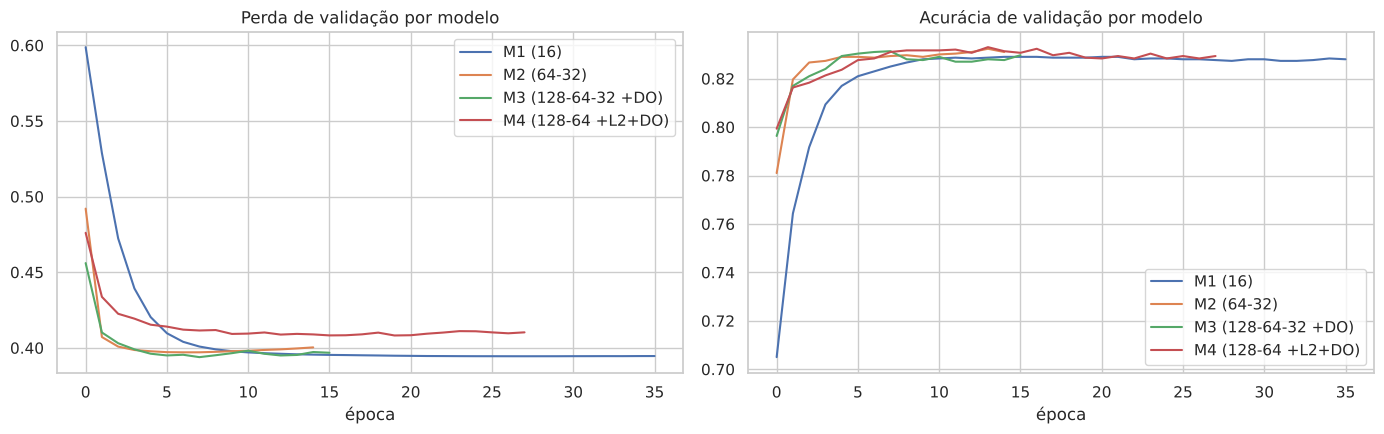

In [6]:
best = comp['F1 val'].round(3).sort_values(ascending=False)
cands = comp[comp['F1 val'].round(3) == best.iloc[0]]
BEST = cands['val_loss'].idxmin()
print('Modelo selecionado:', BEST)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for n, h in hist.items():
    ax[0].plot(h['val_loss'], label=n); ax[1].plot(h['val_accuracy'], label=n)
ax[0].set_title('Perda de validação por modelo'); ax[1].set_title('Acurácia de validação por modelo')
for a in ax: a.set_xlabel('época'); a.legend()
plt.tight_layout(); plt.savefig(FIG/'comparacao_val.png', dpi=130); plt.show()
comp.round(4).to_csv(ROOT/'reports'/'comparacao_arquiteturas.csv')

## 7. Modelo selecionado: curvas, matriz de confusão e avaliação final no teste

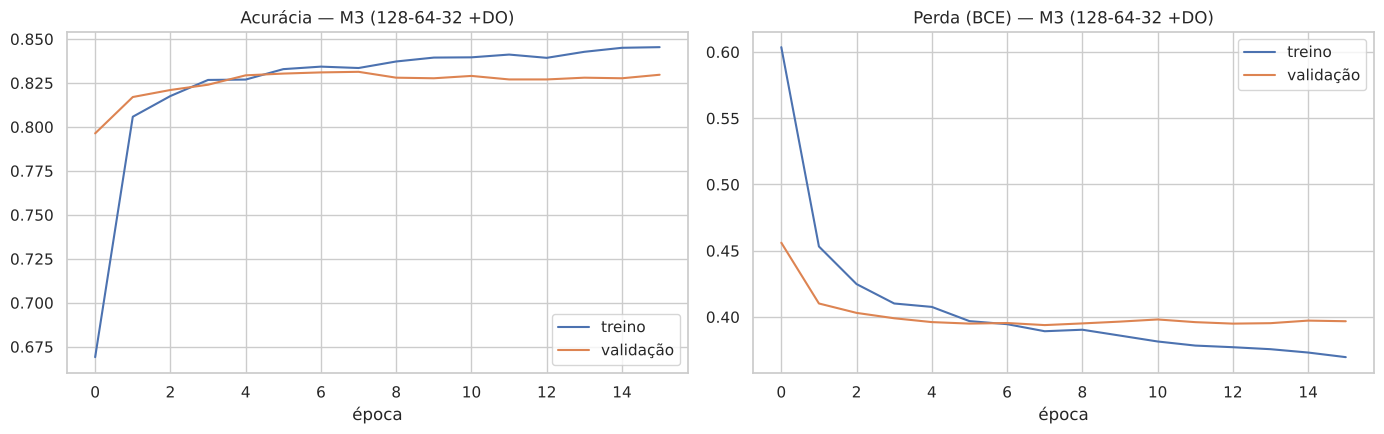

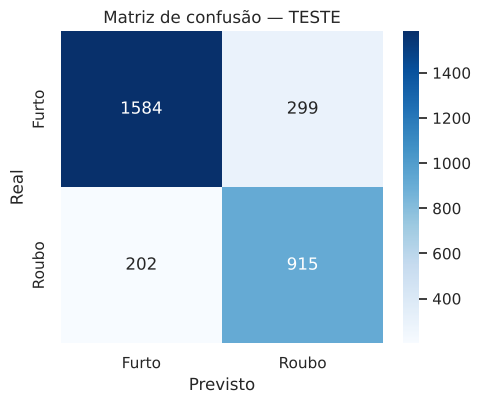

              precision    recall  f1-score   support

       Furto      0.887     0.841     0.863      1883
       Roubo      0.754     0.819     0.785      1117

    accuracy                          0.833      3000
   macro avg      0.820     0.830     0.824      3000
weighted avg      0.837     0.833     0.834      3000


Teste final:


,acuracia,precision,recall,f1
Classe majoritária (chute),0.6277,NaN,0.0000,0.0000
Regressão logística,0.8340,0.7607,0.8084,0.7839
MLP escolhida: M3 (128-64-32 +DO),0.8330,0.7537,0.8192,0.7851


In [7]:
h, m = hist[BEST], models[BEST]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(h['accuracy'], label='treino'); ax[0].plot(h['val_accuracy'], label='validação'); ax[0].set_title(f'Acurácia — {BEST}')
ax[1].plot(h['loss'], label='treino'); ax[1].plot(h['val_loss'], label='validação'); ax[1].set_title(f'Perda (BCE) — {BEST}')
for a in ax: a.set_xlabel('época'); a.legend()
plt.tight_layout(); plt.savefig(FIG/'curvas_modelo_escolhido.png', dpi=130); plt.show()

pte = m.predict(Xte, verbose=0).ravel(); yh = (pte >= 0.5).astype(int)
mt = metrics(yte, pte)
cm = confusion_matrix(yte, yh)
plt.figure(figsize=(5, 4.2)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Furto','Roubo'], yticklabels=['Furto','Roubo'])
plt.xlabel('Previsto'); plt.ylabel('Real'); plt.title('Matriz de confusão — TESTE'); plt.tight_layout(); plt.savefig(FIG/'matriz_confusao.png', dpi=130); plt.show()
print(classification_report(yte, yh, target_names=['Furto','Roubo'], digits=3))

# Referências: o modelo supera o "chute" e uma regressão logística?
maj = max(yte.mean(), 1-yte.mean())
lr = LogisticRegression(max_iter=2000).fit(Xtr, ytr); mlr = metrics(yte, lr.predict_proba(Xte)[:,1])
ref = pd.DataFrame({'Classe majoritária (chute)': {'acuracia': maj, 'precision': np.nan, 'recall': 0.0, 'f1': 0.0},
                    'Regressão logística': mlr, f'MLP escolhida: {BEST}': mt}).T
print('\nTeste final:'); display(ref.round(4))

## 8. Diagnóstico de overfitting / underfitting

In [8]:
g = comp['gap acc (treino-val)']
print(comp[['acc treino','acc val','gap acc (treino-val)','val_loss','épocas (melhor)']].round(4))
last = hist[BEST]
print(f'\n{BEST}: perda treino final={last["loss"][-1]:.4f} | perda val final={last["val_loss"][-1]:.4f} | melhor época={int(np.argmin(last["val_loss"]))+1}')
print(f'Acurácia teste={mt["acuracia"]:.4f} vs validação={comp.loc[BEST,"acc val"]:.4f} (diferença pequena => boa generalização).')

                    acc treino  acc val  gap acc (treino-val)  val_loss  \
modelo                                                                    
M1 (16)                 0.8361   0.8277                0.0085    0.3944   
M2 (64-32)              0.8379   0.8287                0.0093    0.3970   
M3 (128-64-32 +DO)      0.8426   0.8313                0.0113    0.3939   
M4 (128-64 +L2+DO)      0.8454   0.8287                0.0167    0.4082   

                    épocas (melhor)  
modelo                               
M1 (16)                          28  
M2 (64-32)                        7  
M3 (128-64-32 +DO)                8  
M4 (128-64 +L2+DO)               20  

M3 (128-64-32 +DO): perda treino final=0.3697 | perda val final=0.3968 | melhor época=8
Acurácia teste=0.8330 vs validação=0.8313 (diferença pequena => boa generalização).


**Análise (baseada nas tabelas e curvas acima).**
- **Overfitting:** em todos os modelos a diferença de acurácia treino−validação é pequena (< 2 p.p.), então não há overfitting severo. O sinal aparece de forma leve nas redes maiores: o M2 atinge a melhor `val_loss` já nas primeiras épocas (a perda de validação volta a subir enquanto a de treino continua caindo) e o M4 tem o maior gap treino−validação. O *early stopping* interrompe o treino no melhor ponto.
- **Underfitting:** o M1 (16 neurônios) tem acurácia de treino ≈ validação e desempenho quase igual ao das redes maiores — não há subajuste relevante; a capacidade extra de rede pouco ajuda.
- **Regularização:** Dropout (M3) deu a melhor `val_loss` e o melhor F1 de validação; L2 + LR menor (M4) não trouxe ganho adicional.
- **Teto de desempenho:** as quatro arquiteturas ficam praticamente empatadas (diferenças de ~0,5 p.p. no F1, dentro do ruído de uma validação de 3.000 exemplos), e a regressão logística obtém resultado equivalente. O limite vem da **informação nos atributos** (sem a descrição do crime — que foi excluída por ser vazamento — parte dos casos é de fato ambígua), não do tamanho da rede.

## 9. Exportação do modelo para a aplicação web

In [9]:
m.save(ROOT/'model'/'mlp_roubo_furto.keras')
W = {}
dense = [l for l in m.layers if isinstance(l, keras.layers.Dense)]
for i, l in enumerate(dense):
    W[f'W{i}'], W[f'b{i}'] = l.get_weights()
np.savez(ROOT/'model'/'mlp_weights.npz', **W)   # permite inferência só com NumPy (app leve)

def forward_numpy(X):
    a = X
    for i in range(len(dense)-1): a = np.maximum(a @ W[f'W{i}'] + W[f'b{i}'], 0)
    z = a @ W[f'W{len(dense)-1}'] + W[f'b{len(dense)-1}']
    return (1/(1+np.exp(-z))).ravel()
print('Diferença máxima Keras x NumPy:', np.abs(forward_numpy(Xte) - pte).max())
res = {'modelo': BEST, 'config': CONFIGS[BEST], 'teste': {k: float(v) for k, v in mt.items()}, 'n_features': int(Xtr.shape[1]),
       'n_treino': len(tr), 'n_val': len(va), 'n_teste': len(te), 'matriz_confusao': cm.tolist(),
       'comparacao': comp.round(4).reset_index().to_dict('records'),
       'referencias': {'majoritaria_acc': float(maj), 'logistica': {k: float(v) for k, v in mlr.items()}}}
json.dump(res, open(ROOT/'model'/'metrics.json','w'), ensure_ascii=False, indent=1)

Diferença máxima Keras x NumPy: 5.9604645e-08


## 10. Conclusões, limitações e uso de IA generativa
- **Resultado:** a MLP escolhida classifica corretamente cerca de 83% das ocorrências do conjunto de teste (contra ~63% de um classificador que sempre responde "furto"), com F1 ≈ 0,79 para roubo. Os números exatos estão na seção 7 e em `model/metrics.json`.
- **Comparação honesta:** as 4 arquiteturas e uma regressão logística de referência têm desempenho muito próximo. A escolha do modelo (M3, pela validação) é defensável, mas a principal lição é que *mais camadas não significam mais acerto* quando a informação de entrada é limitada.
- **Interpretação correta:** a probabilidade exibida é "dado que uma ocorrência com estas características foi registrada, quão compatível ela é com roubo vs. furto". **Não** é risco de crime em um bairro/horário.
- **Limitações:** (i) dados administrativos de boletins — sujeitos a subnotificação e a erros de preenchimento/classificação; (ii) apenas celulares, 2024–2025; (iii) cerca de metade dos registros não tem hora exata (usamos o período); (iv) bairros raros foram agrupados em "Outros"; (v) o modelo reflete padrões de *registro*, e não deve ser usado para decisões sobre pessoas ou policiamento; (vi) o teste é aleatório no tempo (sem validação temporal).
- **Possíveis melhorias:** validação temporal, mais registros, atributos adicionais de contexto, calibração das probabilidades e comparação com modelos de árvores.
- **Uso de IA generativa:** o Claude (Anthropic) foi usado para explorar a base, escrever o código de pré-processamento, treino e aplicação web e rascunhar a documentação. A equipe revisou o código, verificou a ausência de vazamento (exclusão de rubrica, conduta, circunstância, desdobramento etc.), conferiu os resultados e é responsável por explicá-los.
